# 02. Data Preprocessing (Aligned with `Data Preprocessing.pdf`)

**Project:** Classical Supervised Learning (Regression) — CarDekho Used Car Price Prediction  
**Input Dataset:** `../dataset/raw/car.csv` (4,000 rows × 8 columns)  
**Output Directory:** `../dataset/processed/`  

This notebook implements every stage taught in **`Data Preprocessing.pdf`** (Sections 1–6) in strict, leakage-free order:
1. **Section 1 — Types of Data:** Classify features as Nominal, Ordinal, Interval, or Ratio.
2. **Section 2 — Types of Variable:** Separate Independent explanatory variables ($X$) from Dependent response variable ($y = \text{selling\_price}$).
3. **Section 3 — Data Cleaning:**
   - *3.1 Low Variation:* Check `var(x)` and `std(x)` to drop zero-variance features.
   - *3.2 Missing Value:* Scan for `NaN` and disguised placeholders (`NA`, `n/a`, `""`, `?`, `-1`, `-99`, `-999`, `null`) + Vishal Patel thresholds (`<50%` impute / `>95%` drop).
   - *3.3 Outlier:* Boxplot visualization + Z-score ($-3 < Z < 3$) & IQR ($[Q_1 - 1.5\cdot\text{IQR},\; Q_3 + 1.5\cdot\text{IQR}]$) analysis + Linear Regression sensitivity check.
   - *3.4 Imbalanced Dataset / SMOTE:* Explicitly noted as classification-only (not applicable to continuous regression).
   - *Duplicate & String Cleaning:* Remove exact duplicates before splitting.
4. **Section 4 — Feature Scaling:** Standardization (Z-score) & Min-Max Normalization comparison.
5. **Section 5 — Feature Encoding:** Ordinal/Label Encoding (ordered `owner`) & One-Hot Encoding (nominal categories).
6. **Section 6 — Feature Correlation:** Pearson correlation $r_{xy}$ for feature selection & multicollinearity removal (`year` vs. `car_age`).

In [1]:
import os
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler

os.makedirs("../dataset/processed", exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Types of Data & Types of Variable (`Data Preprocessing.pdf` §1–2)

Per **Section 1 (Types of Data)** and **Section 2 (Types of Variable)**:
- **Categorical (Qualitative):**
  - **Nominal (no order):** `name` (used to engineer `brand`), `fuel`, `seller_type`, `transmission`
  - **Ordinal (ranked order):** `owner` (`Test Drive Car` < `First Owner` < `Second Owner` < `Third Owner` < `Fourth & Above Owner`)
- **Numerical (Quantitative):**
  - **Interval (no true zero):** `year` (converted to Ratio `car_age = 2020 - year`)
  - **Ratio (has true zero):** `km_driven`, `selling_price`
- **Variable Roles:** Independent predictors $X$ (`name`, `year`, `km_driven`, `fuel`, `seller_type`, `transmission`, `owner`) $\rightarrow h(X) \rightarrow$ Dependent response $y$ (`selling_price` in INR).

In [2]:
df = pd.read_csv("../dataset/raw/car.csv")
print("Initial raw shape:", df.shape)

data_taxonomy = pd.DataFrame([
    {"Column": "name", "Raw_Dtype": str(df["name"].dtype), "Data_Category": "Categorical", "Scale": "Nominal", "Variable_Role": "Independent (X -> brand)"},
    {"Column": "year", "Raw_Dtype": str(df["year"].dtype), "Data_Category": "Numerical", "Scale": "Interval", "Variable_Role": "Independent (X -> car_age)"},
    {"Column": "km_driven", "Raw_Dtype": str(df["km_driven"].dtype), "Data_Category": "Numerical", "Scale": "Ratio", "Variable_Role": "Independent (X)"},
    {"Column": "fuel", "Raw_Dtype": str(df["fuel"].dtype), "Data_Category": "Categorical", "Scale": "Nominal", "Variable_Role": "Independent (X)"},
    {"Column": "seller_type", "Raw_Dtype": str(df["seller_type"].dtype), "Data_Category": "Categorical", "Scale": "Nominal", "Variable_Role": "Independent (X)"},
    {"Column": "transmission", "Raw_Dtype": str(df["transmission"].dtype), "Data_Category": "Categorical", "Scale": "Nominal", "Variable_Role": "Independent (X)"},
    {"Column": "owner", "Raw_Dtype": str(df["owner"].dtype), "Data_Category": "Categorical", "Scale": "Ordinal", "Variable_Role": "Independent (X)"},
    {"Column": "selling_price", "Raw_Dtype": str(df["selling_price"].dtype), "Data_Category": "Numerical", "Scale": "Ratio", "Variable_Role": "Dependent Target (y)"},
])
print(data_taxonomy.to_string(index=False))

Initial raw shape: (4000, 8)
       Column Raw_Dtype Data_Category    Scale              Variable_Role
         name       str   Categorical  Nominal   Independent (X -> brand)
         year     int64     Numerical Interval Independent (X -> car_age)
    km_driven     int64     Numerical    Ratio            Independent (X)
         fuel       str   Categorical  Nominal            Independent (X)
  seller_type       str   Categorical  Nominal            Independent (X)
 transmission       str   Categorical  Nominal            Independent (X)
        owner       str   Categorical  Ordinal            Independent (X)
selling_price     int64     Numerical    Ratio       Dependent Target (y)


## 2. Data Cleaning — Missing Values, Placeholders & Duplicates (`Data Preprocessing.pdf` §3.2)

Per **Section 3.2**, missing values can appear not only as `NaN`, but also as `NA`, `n/a`, `empty string`, `?`, `-1`, `-99`, `-999`, or `null`. We also check missing percentages against **Vishal Patel's rule** (`< 50%` → impute; `> 95%` → discard column), clean extra whitespace in strings, and remove exact duplicates **before splitting** so identical cars cannot leak across train and test sets.

In [3]:
# Normalize whitespace in text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

# Scan for standard NaNs AND disguised missing placeholders from Data Preprocessing.pdf p.12
str_placeholders = {"", "na", "n/a", "null", "none", "?", "-"}
num_sentinels = {-1, -99, -999, 9999}

missing_report = []
for col in df.columns:
    null_cnt = int(df[col].isnull().sum())
    if df[col].dtype == "object":
        ph_cnt = int(df[col].str.lower().isin(str_placeholders).sum())
    else:
        ph_cnt = int(df[col].isin(num_sentinels).sum())
    total_miss = null_cnt + ph_cnt
    pct_miss = total_miss / len(df) * 100
    action = "OK (0% missing)" if total_miss == 0 else ("Discard (>95%)" if pct_miss > 95 else ("Impute (<50%)" if pct_miss < 50 else "No Imputation (50-95%)"))
    missing_report.append({"Column": col, "NaN": null_cnt, "Placeholders": ph_cnt, "Missing_%": round(pct_miss, 2), "Vishal_Patel_Rule": action})

print(pd.DataFrame(missing_report).to_string(index=False))
assert df.isnull().sum().sum() == 0, "Unexpected missing values detected!"

# Remove exact duplicate rows before splitting
n_before = len(df)
n_dups = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nRemoved {n_dups} exact duplicate rows: {n_before} -> {len(df)} unique rows.")
assert df.duplicated().sum() == 0

       Column  NaN  Placeholders  Missing_% Vishal_Patel_Rule
         name    0             0        0.0   OK (0% missing)
         year    0             0        0.0   OK (0% missing)
selling_price    0             0        0.0   OK (0% missing)
    km_driven    0             0        0.0   OK (0% missing)
         fuel    0             0        0.0   OK (0% missing)
  seller_type    0             0        0.0   OK (0% missing)
 transmission    0             0        0.0   OK (0% missing)
        owner    0             0        0.0   OK (0% missing)

Removed 663 exact duplicate rows: 4000 -> 3337 unique rows.


## 3. Data Cleaning — Outlier Detection: Boxplot, Z-Score & IQR (`Data Preprocessing.pdf` §3.3)

Per **Section 3.3**, Linear Regression is sensitive to outliers. We apply both methods taught in class:
- **Z-Score (Gaussian check):** $\text{Z-score}(x) = \frac{x - \text{mean}(x)}{\text{std}(x)}$, normal range $-3 < \text{Z-score}(x) < 3$
- **Interquartile Range (IQR):** $\text{IQR} = Q_3 - Q_1$, normal range $[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$

**Domain Interpretation (`Data Preprocessing.pdf` p. 16):**
- **Data entry error:** A used `Second Owner` car (`Mahindra Quanto C6`) reporting `km_driven = 1` (< 100 km) is a data-entry mistake and is removed.
- **Natural novelties:** High `selling_price` values (> ₹1.2M INR) represent genuine luxury brands (Mercedes, BMW, Audi) and are **retained** so the model learns luxury pricing.

> **Note on Section 3.4 (Imbalanced Dataset / SMOTE):** Undersampling, Oversampling, and SMOTE apply strictly to *classification* problems with discrete class imbalance (`Data Preprocessing.pdf` p. 28–31) and are **not applied** to our continuous regression target `selling_price`.

selling_price  | IQR=[-400,000.0, 1,200,000.0] -> 160 outliers | |Z|>3 ->  53 outliers
km_driven      | IQR=[ -47,500.0,   172,500.0] ->  96 outliers | |Z|>3 ->  45 outliers
year           | IQR=[   2,001.0,     2,025.0] ->  34 outliers | |Z|>3 ->  34 outliers
Removing 1 data-entry anomaly row(s) with km_driven < 100 (non-Test-Drive).
Shape after cleaning: (3336, 8)


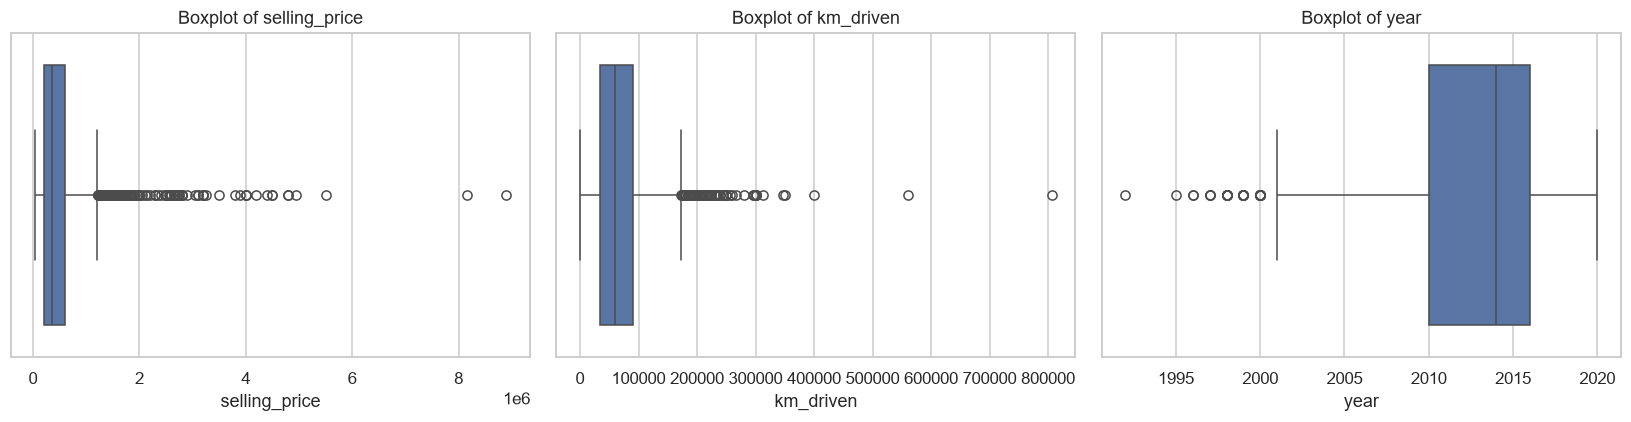

In [4]:
def report_outliers(series, name):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_count = int(((series < low) | (series > high)).sum())
    z = (series - series.mean()) / series.std()
    z_count = int((z.abs() > 3).sum())
    print(f"{name:<14} | IQR=[{low:>10,.1f}, {high:>11,.1f}] -> {iqr_count:>3} outliers | |Z|>3 -> {z_count:>3} outliers")

for col in ["selling_price", "km_driven", "year"]:
    report_outliers(df[col], col)

# Boxplot visualization per Data Preprocessing.pdf p. 23
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["selling_price", "km_driven", "year"]):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

# Filter clear data-entry anomaly: non-Test-Drive cars with km_driven < 100
anomaly_mask = (df["km_driven"] < 100) & (df["owner"] != "Test Drive Car")
print(f"Removing {int(anomaly_mask.sum())} data-entry anomaly row(s) with km_driven < 100 (non-Test-Drive).")
df = df[~anomaly_mask].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

## 4. Feature Engineering, Low Variation Check & Correlation Selection (`Data Preprocessing.pdf` §3.1 & §6)

1. Engineer `brand` from `name` (grouping rare brands `< 15` rows into `'Other'`) and `car_age = 2020 - year`.
2. **Section 3.1 (Low Variation):** Compute $\text{var}(x) = \frac{1}{n}\sum(x_i - \bar{x})^2$ and $\text{std}(x) = \sqrt{\text{var}(x)}$ to verify **zero-variance features** do not exist (any single-value feature would be dropped).
3. **Section 6 (Feature Correlation):** Compute **Pearson Correlation** $r_{xy} \in [-1, +1]$ to detect redundant collinear features (`r(year, car_age) = -1.0`) and drop raw `year` and raw `name`.

Grouping 12 rare brands (<15 rows) into 'Other': ['Land', 'Jaguar', 'Mitsubishi', 'Volvo', 'Jeep', 'Ambassador', 'MG', 'OpelCorsa', 'Kia', 'Isuzu', 'Daewoo', 'Force']
Pearson r(year, car_age): -1.0 -> drop redundant 'year' and raw 'name'

Low Variation Check (drop if Variance == 0):
                   Variance    Std_Dev  Unique_Values
selling_price  2.619494e+11  511809.94            434
car_age        1.817000e+01       4.26             27
km_driven      2.256593e+09   47503.61            738
owner_ord      5.400000e-01       0.73              5

Pearson Correlation Matrix:
               selling_price  car_age  km_driven  owner_ord
selling_price         1.0000  -0.4252    -0.1892    -0.2396
car_age              -0.4252   1.0000     0.4136     0.4735
km_driven            -0.1892   0.4136     1.0000     0.3220
owner_ord            -0.2396   0.4735     0.3220     1.0000


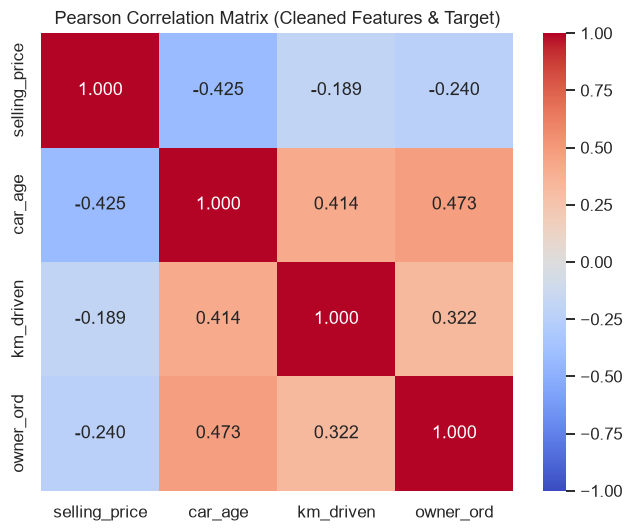

In [5]:
REFERENCE_YEAR = 2020
df["brand"] = df["name"].str.split().str[0]

brand_counts = df["brand"].value_counts()
rare_brands = brand_counts[brand_counts < 15].index
print(f"Grouping {len(rare_brands)} rare brands (<15 rows) into 'Other': {list(rare_brands)}")
df["brand"] = df["brand"].replace(rare_brands, "Other")

df["car_age"] = REFERENCE_YEAR - df["year"]
print("Pearson r(year, car_age):", round(df["year"].corr(df["car_age"]), 4), "-> drop redundant 'year' and raw 'name'")

df_cleaned = df.drop(columns=["name", "year"]).copy()
df_cleaned.to_csv("../dataset/processed/car_cleaned.csv", index=False)

# Low Variation check (Data Preprocessing.pdf §3.1)
owner_order = [
    "Test Drive Car",
    "First Owner",
    "Second Owner",
    "Third Owner",
    "Fourth & Above Owner",
]
owner_map = {label: idx for idx, label in enumerate(owner_order)}

num_check = df_cleaned[["selling_price", "car_age", "km_driven"]].copy()
num_check["owner_ord"] = df_cleaned["owner"].map(owner_map)

var_std_df = pd.DataFrame({
    "Variance": num_check.var(ddof=0),
    "Std_Dev": num_check.std(ddof=0),
    "Unique_Values": num_check.nunique(),
})
print("\nLow Variation Check (drop if Variance == 0):")
print(var_std_df.round(2))
assert (var_std_df["Variance"] > 0).all(), "Zero-variance feature detected!"

# Pearson Correlation Heatmap (Data Preprocessing.pdf §6)
corr_mat = num_check.corr(method="pearson")
print("\nPearson Correlation Matrix:")
print(corr_mat.round(4))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_mat, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Pearson Correlation Matrix (Cleaned Features & Target)")
plt.tight_layout()
plt.show()

## 5. Leakage-Free Train / Validation / Test Split (70% / 15% / 15%)

Separate $X$ (independent features) and $y$ (`selling_price`), then split **before** fitting encoders and scalers so validation and test statistics never leak into training.

In [6]:
X = df_cleaned.drop(columns=["selling_price"])
y = df_cleaned["selling_price"]

price_bins = pd.qcut(y, q=4, labels=False)

X_dev, X_test, y_dev, y_test, bins_dev, _ = train_test_split(
    X, y, price_bins,
    test_size=0.15,
    random_state=42,
    stratify=price_bins,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=bins_dev,
)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (2334, 7), Val: (501, 7), Test: (501, 7)


## 6. Feature Encoding & Feature Scaling (`Data Preprocessing.pdf` §4–5)

- **Section 5 — Feature Encoding:**
  - **Label / Ordinal Encoding (`owner`):** Ordered values `Test Drive Car` (0) < `First Owner` (1) < `Second Owner` (2) < `Third Owner` (3) < `Fourth & Above Owner` (4).
  - **One-Hot Encoding (`fuel`, `seller_type`, `transmission`, `brand`):** Binary `0`/`1` dummy variables for unordered nominal features.
- **Section 4 — Feature Scaling:**
  - **Standardization (Z-score):** $x_{\text{new}} = \frac{x - \text{mean}(x)}{\text{std}(x)}$ (mean `0`, std `1`) — selected as our primary scaler because `km_driven` spans vastly larger magnitudes ($10^5$) than `car_age` ($10^1$) and contains upper-tail outliers.
  - **Min-Max Normalization:** $x_{\text{new}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$ (range `[0, 1]`) — shown side-by-side for direct comparison.

In [7]:
numeric_features = ["car_age", "km_driven"]
ordinal_features = ["owner"]
nominal_features = ["fuel", "seller_type", "transmission", "brand"]

ordinal_pipeline = Pipeline([
    ("ord", OrdinalEncoder(categories=[owner_order])),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("ord", ordinal_pipeline, ordinal_features),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_features),
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_proc, columns=feature_names)
X_val_df = pd.DataFrame(X_val_proc, columns=feature_names)
X_test_df = pd.DataFrame(X_test_proc, columns=feature_names)

# Compare Standardization vs Min-Max Normalization on X_train['km_driven']
mm_km = MinMaxScaler().fit_transform(X_train[["km_driven"]])[:, 0]
scaler_stats = pd.DataFrame({
    "Method": ["Raw km_driven", "Standardization (Z-score)", "Min-Max Normalization"],
    "Mean": [X_train["km_driven"].mean(), X_train_df["num__km_driven"].mean(), mm_km.mean()],
    "Std": [X_train["km_driven"].std(), X_train_df["num__km_driven"].std(), mm_km.std()],
    "Min": [X_train["km_driven"].min(), X_train_df["num__km_driven"].min(), mm_km.min()],
    "Max": [X_train["km_driven"].max(), X_train_df["num__km_driven"].max(), mm_km.max()],
})
print("Feature Scaling Comparison (Train km_driven):")
print(scaler_stats.round(4).to_string(index=False))

Feature Scaling Comparison (Train km_driven):
                   Method       Mean        Std       Min        Max
            Raw km_driven 69752.1787 46230.9270 1000.0000 400000.000
Standardization (Z-score)     0.0000     1.0002   -1.4875      7.145
    Min-Max Normalization     0.1723     0.1158    0.0000      1.000


## 7. Save Processed Datasets & Verify All Constraints

In [8]:
X_train_df.to_csv("../dataset/processed/X_train.csv", index=False)
X_val_df.to_csv("../dataset/processed/X_val.csv", index=False)
X_test_df.to_csv("../dataset/processed/X_test.csv", index=False)

y_train.to_csv("../dataset/processed/y_train.csv", index=False)
y_val.to_csv("../dataset/processed/y_val.csv", index=False)
y_test.to_csv("../dataset/processed/y_test.csv", index=False)

raw_dev = X_dev.copy()
raw_dev["selling_price"] = y_dev.values
raw_dev.to_csv("../dataset/processed/raw_train_dev.csv", index=False)

joblib.dump(preprocessor, "../dataset/processed/preprocessor.joblib")

# Post-split validation assertions
assert len(X_train_df) + len(X_val_df) + len(X_test_df) == len(df_cleaned)
assert X_train_df.shape[1] == X_val_df.shape[1] == X_test_df.shape[1]
assert X_train_df.isnull().sum().sum() == 0
assert X_val_df.isnull().sum().sum() == 0
assert X_test_df.isnull().sum().sum() == 0
assert abs(X_train_df["num__km_driven"].mean()) < 1e-6
assert abs(X_train_df["num__car_age"].mean()) < 1e-6

print("All validation checks PASSED!")
print("Final encoded feature count:", X_train_df.shape[1])
print("Saved artifacts:", sorted(os.listdir("../dataset/processed")))

All validation checks PASSED!
Final encoded feature count: 31
Saved artifacts: ['X_test.csv', 'X_train.csv', 'X_val.csv', 'car_cleaned.csv', 'preprocessor.joblib', 'raw_train_dev.csv', 'y_test.csv', 'y_train.csv', 'y_val.csv']
